# 4. Diagnóstico de residuos

Analizamos los residuos `resid = y_real − y_pred` del primer paso del horizonte (h = 1). Aplicamos el test BDS (Broock et al., 1996), cuya hipótesis nula es que los residuos son independientes e idénticamente distribuidos: un p-valor mayor que 0.05 no rechaza esa hipótesis y es la señal deseada. Lo calculamos sobre validación (por fold y estrategia) y sobre el hold-out del modelo final, y lo complementamos con Ljung-Box y la ACF de los residuos.

In [1]:
# Rutas: en Colab se usa la carpeta de Drive; en el repositorio, la raíz del proyecto.
import os, glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DRIVE = Path("/content/drive/MyDrive/tarea2_series")
if DRIVE.exists():
    BASE, FIGS = DRIVE, DRIVE / "figs"
else:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FIGS = BASE / "notebooks" / "figs"
RESULTS = BASE / os.environ.get("T2_RESULTS_DIR", "results")
FIGS.mkdir(parents=True, exist_ok=True)

LAGS, HS, ESTRATEGIAS = [7, 14, 21, 28], [7, 14, 21, 28], ["gk", "fc", "kf"]
NOMBRE = {"gk": "Group K-Fold", "fc": "Forward Chaining", "kf": "K-Fold"}
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # orden categorico fijo
COL_EST = dict(zip(ESTRATEGIAS, COL))
COL_LAG = dict(zip(LAGS, COL))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.prop_cycle": plt.cycler(color=COL), "lines.linewidth": 1.6,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.labelsize": 10})

df = pd.read_csv(BASE / "data" / "btc_1d.csv", parse_dates=["date"])
y = df["close"].to_numpy(float)
DATES = df["date"].to_numpy()
N_HOLD = max(int(len(y) * 0.10), 56)
N_CV = len(y) - N_HOLD


def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight", dpi=150)

In [2]:
def cargar_registros():
    R = {}
    for f in sorted(glob.glob(str(RESULTS / "raw" / "*.jsonl"))):
        for line in open(f):
            if line.strip():
                r = json.loads(line); R[r["id"]] = r
    return list(R.values())

REG = cargar_registros()
print(f"{len(REG)} registros en {RESULTS / 'raw'}")
print(pd.Series([r["phase"] for r in REG]).value_counts().to_string())

7435 registros en /content/drive/MyDrive/tarea2_series/results/raw
search       7211
top5           80
eval_rep       48
detail         48
eval_own       32
final_rep      16


## 4.1 BDS sobre validación

In [3]:
DET = {(r["L"], r["H"], r["strat"]): r for r in REG if r["phase"] == "detail"}
filas = []
for (L, H, s), d in DET.items():
    p = [f["bds_p_h1"] for f in d["folds"] if f["bds_p_h1"] is not None]
    filas.append(dict(estrategia=NOMBRE[s], lag=L, H=H, folds_con_bds=len(p),
                      bds_p_medio=np.mean(p) if p else np.nan,
                      folds_p_mayor_005=int(np.sum(np.array(p) > 0.05)) if p else 0))
BDSV = pd.DataFrame(filas).sort_values(["estrategia", "lag", "H"])
BDSV.to_csv(RESULTS / "bds_validacion.csv", index=False)
BDSV[BDSV.estrategia == "Group K-Fold"].pivot(index="lag", columns="H", values="bds_p_medio").round(3)

H,7,14,21,28
lag,,,,
7,0.075,0.119,0.030,0.091
14,0.053,0.000,0.000,0.116
21,0.113,0.032,0.064,0.096
28,0.127,0.241,0.214,0.314


Forward Chaining y K-Fold validan sobre una ventana por fold: un solo residuo h = 1 por fold no permite aplicar BDS, por eso esas filas aparecen vacías.

La tabla resume cada configuración con el promedio de los p-valores de sus cinco folds. Ese promedio es un resumen descriptivo, no un test. Con ese criterio, 12 de las 16 configuraciones quedan por encima de 0.05 y cuatro por debajo (lag 7 con H 21, lag 14 con H 14 y H 21, lag 21 con H 14). El lag 28 tiene los p-valores más altos (0.13 a 0.31).

Hay una advertencia importante sobre esta lectura. En Group K-Fold los residuos de validación de un fold no forman una serie consecutiva: son bloques separados por los bloques de entrenamiento intercalados. El test BDS supone una secuencia temporal continua, y concatenar bloques separados debilita la dependencia que el test busca. Por eso un p-valor alto aquí no es evidencia fuerte de residuos independientes. La prueba más exigente es la del hold-out, donde los residuos sí son consecutivos.

## 4.2 BDS y Ljung-Box sobre el hold-out del modelo final

In [4]:
from statsmodels.tsa.stattools import bds
from statsmodels.stats.diagnostic import acorr_ljungbox
filas, RESID = [], {}
for L in LAGS:
    for H in HS:
        f = RESULTS / "models" / f"own_L{L}_H{H}_preds.npz"
        if not f.exists():
            continue
        z = np.load(f); e = z["real"][:, 0] - z["pred"][:, 0]; RESID[(L, H)] = e
        p_bds = float(np.atleast_1d(bds(e, max_dim=2)[1])[0])
        p_lb = float(acorr_ljungbox(e, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
        filas.append(dict(lag=L, H=H, n=len(e), media_resid=e.mean(), std_resid=e.std(),
                          BDS_pvalue_h1=p_bds, LjungBox10_pvalue=p_lb))
BDSH = pd.DataFrame(filas)
BDSH.to_csv(RESULTS / "bds_holdout.csv", index=False)
BDSH.round(4)

,lag,H,n,media_resid,std_resid,BDS_pvalue_h1,LjungBox10_pvalue
0,7,7,286,-2604.1745,2900.7556,0.0,0.0
1,7,14,279,-4772.4534,3650.7196,0.0,0.0
2,7,21,272,-8173.7290,3750.4509,0.0,0.0
3,7,28,265,-25713.5138,3921.5828,0.0,0.0
4,14,7,286,1606.1239,3264.1563,0.0,0.0
5,14,14,279,-750.8793,4075.8033,0.0,0.0
6,14,21,272,19734.8692,6804.0397,0.0,0.0
7,14,28,265,-24742.9274,3964.5391,0.0,0.0
8,21,7,286,9544.6574,4128.9303,0.0,0.0
9,21,14,279,2870.0038,4065.6676,0.0,0.0


En el hold-out el resultado es claro: BDS y Ljung-Box (10 rezagos) rechazan la independencia en las 16 configuraciones, con p-valores que redondean a 0.000. Los residuos del modelo final no son ruido blanco.

La columna `media_resid` explica gran parte del rechazo. El residuo medio de h = 1 va de −25 714 USD (lag 7, H 28) a +19 735 USD (lag 14, H 21), cuando la desviación estándar de los residuos ronda 3000 a 4000 USD. Como el residuo es real − predicho, un valor negativo indica que el modelo sobreestima el precio de forma sistemática y uno positivo que lo subestima. En 10 de las 16 configuraciones el valor absoluto del sesgo supera a la desviación estándar. Un residuo con un sesgo persistente que cambia lentamente en el tiempo está autocorrelacionado por construcción, y eso basta para que ambos tests rechacen. Como Ljung-Box, que solo detecta dependencia lineal, ya rechaza, el rechazo de BDS no permite concluir que exista dependencia no lineal adicional.

## 4.3 Residuos del hold-out (lag 14, H 14)

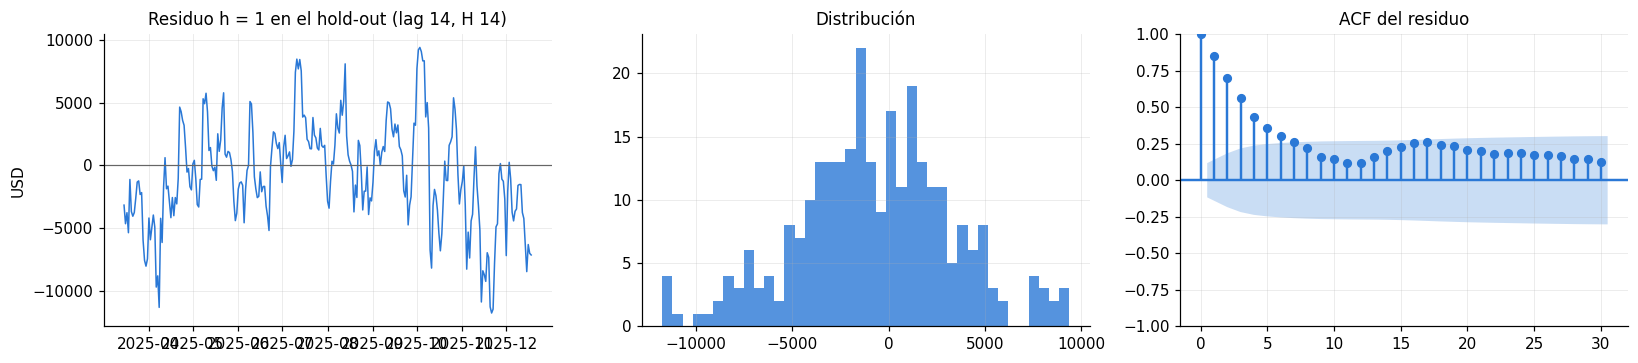

In [5]:
from statsmodels.graphics.tsaplots import plot_acf
def figura_residuos(L, H):
    e = RESID[(L, H)]; t = DATES[N_CV:N_CV + len(e)]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
    ax[0].plot(t, e, color=COL[0], lw=1); ax[0].axhline(0, color="0.4", lw=0.8)
    ax[0].set_title(f"Residuo h = 1 en el hold-out (lag {L}, H {H})"); ax[0].set_ylabel("USD")
    ax[1].hist(e, bins=40, color=COL[0], alpha=0.8); ax[1].set_title("Distribución")
    plot_acf(e, lags=30, ax=ax[2], title="ACF del residuo")
    fig.tight_layout(); guardar(fig, f"residuos_holdout_L{L}_H{H}"); plt.show()

if (14, 14) in RESID:
    figura_residuos(14, 14)

En lag 14 con H 14 el sesgo medio es pequeño (−751 USD), pero el residuo oscila entre −11 000 y +9 000 USD con episodios largos del mismo signo: varias semanas por encima de cero seguidas de varias por debajo. La ACF lo confirma: la autocorrelación del residuo es 0.85 en el rezago 1 y decae despacio, quedando fuera de la banda de confianza hasta cerca del rezago 7 (lectura de la figura). Es el patrón de un error que hereda la persistencia de la serie: cuando el precio se aleja del nivel que la red predice, el error se mantiene durante días. Esto es coherente con lo observado en el notebook 3: la red no reproduce la persistencia del último precio con la exactitud del pronóstico ingenuo.

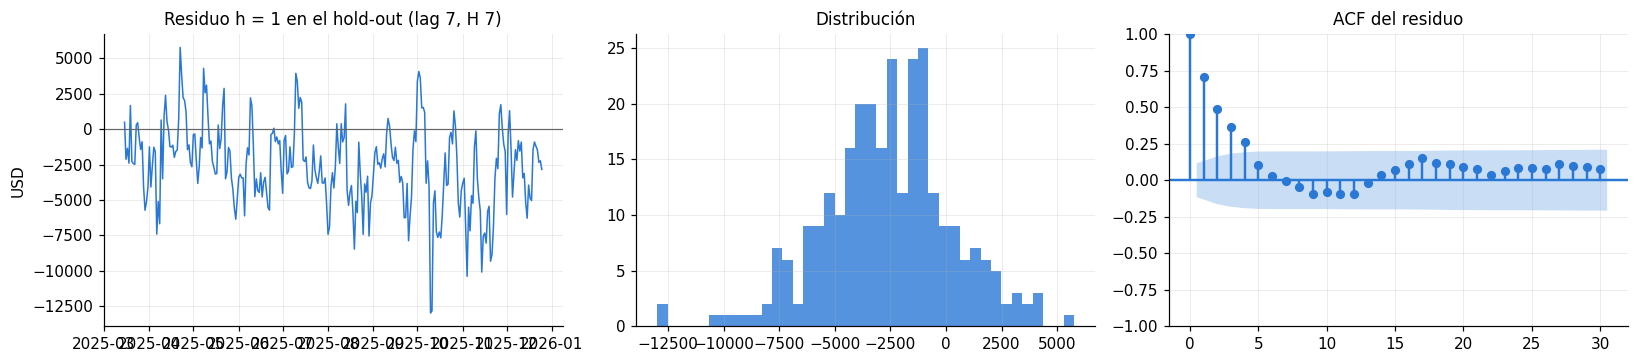

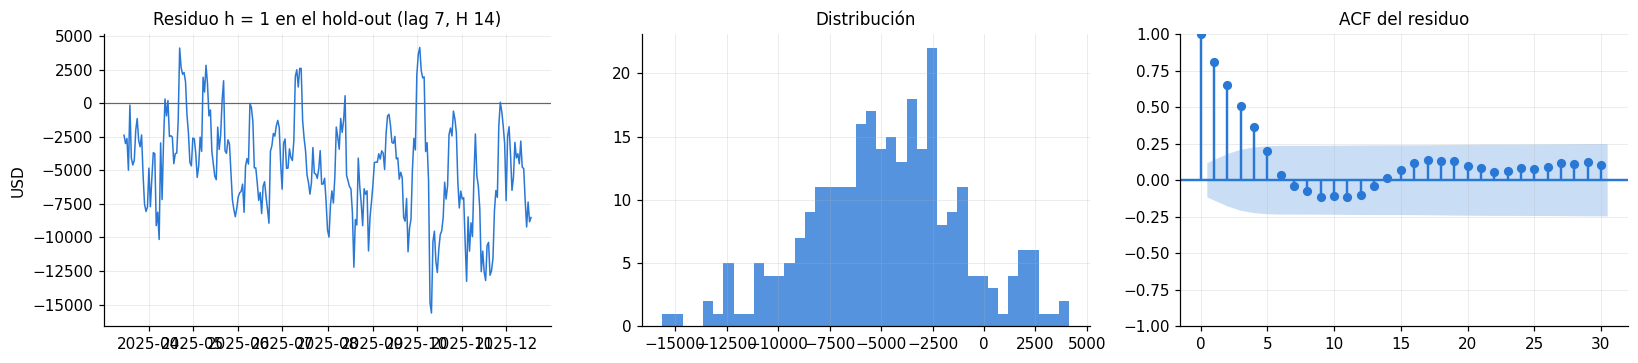

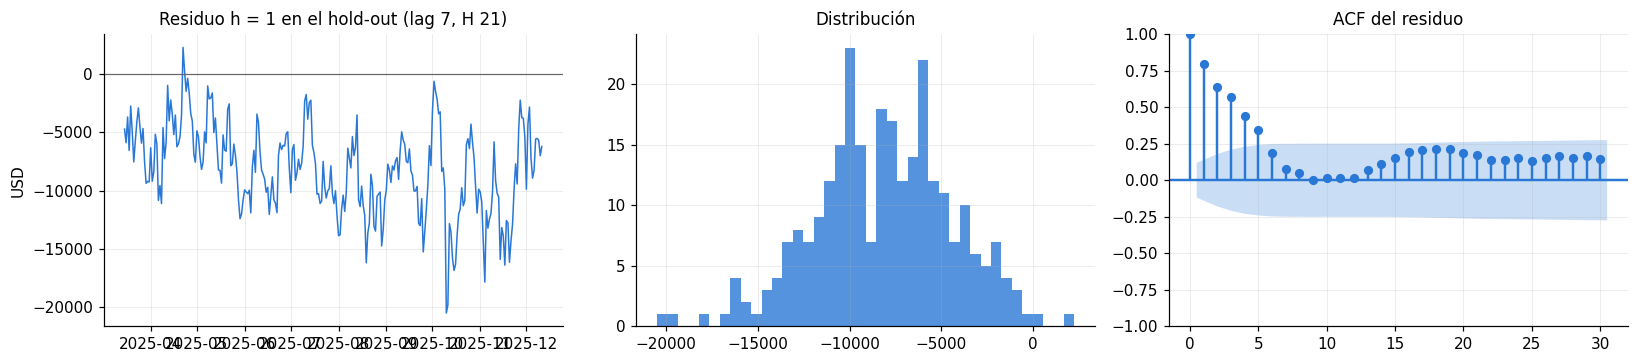

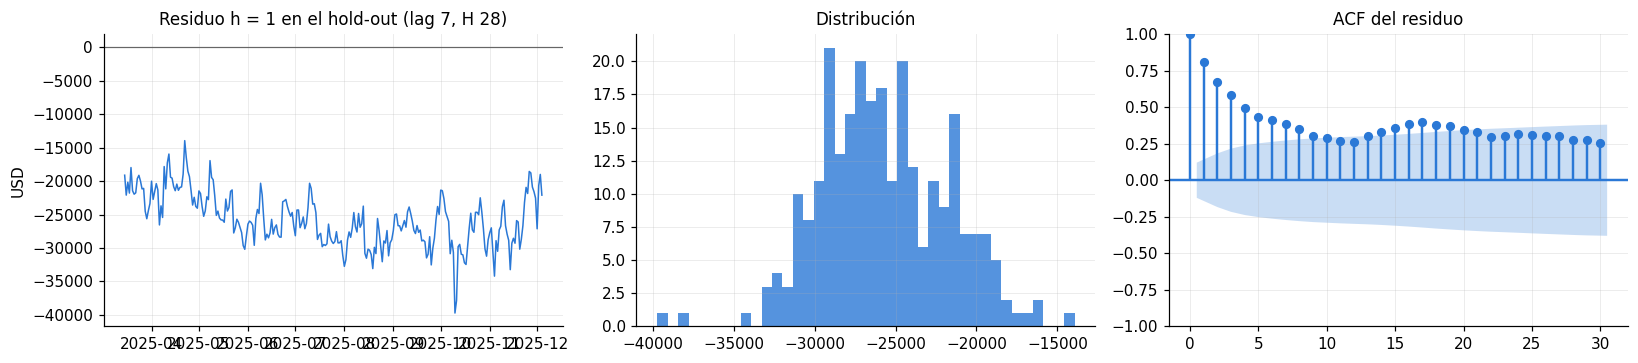

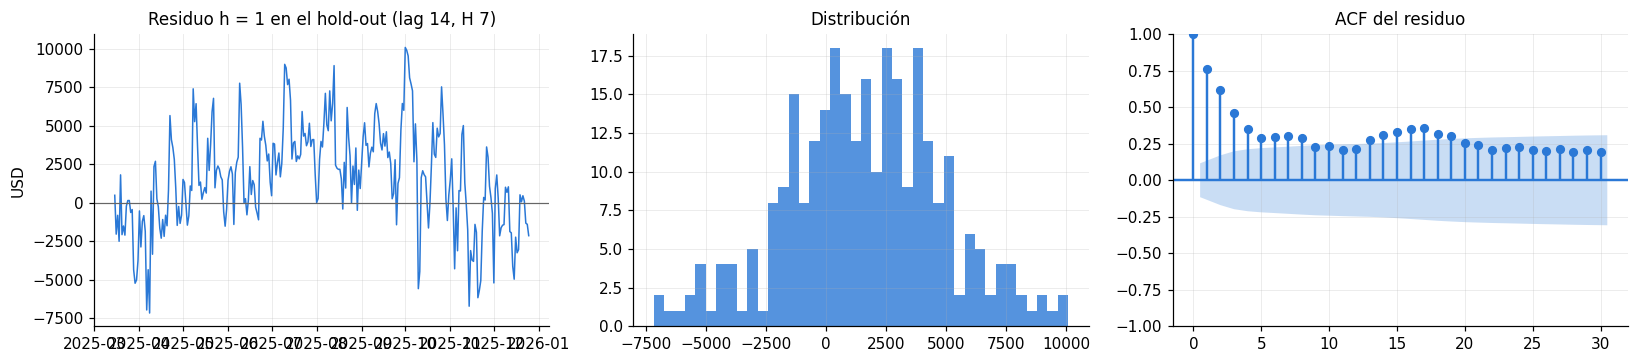

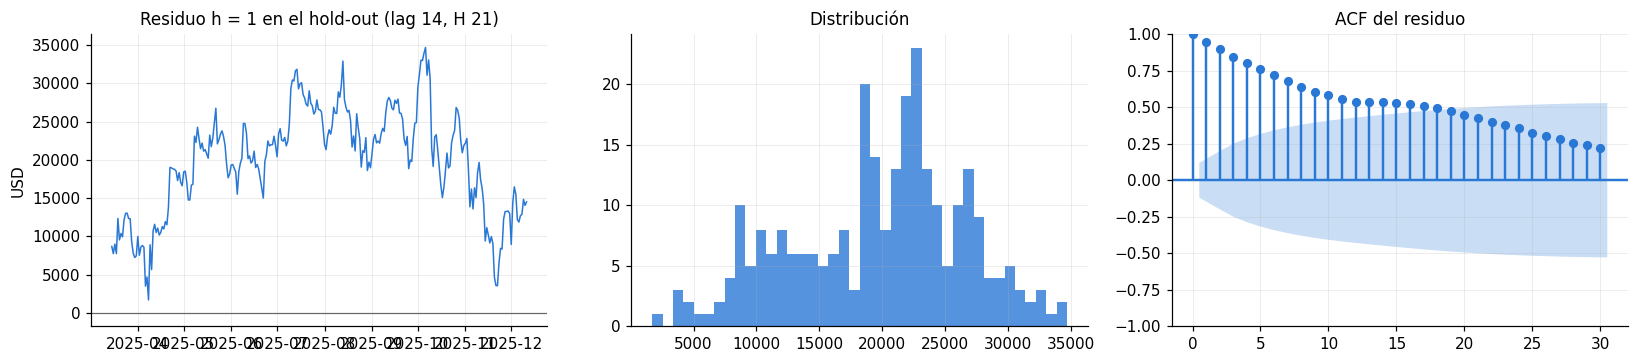

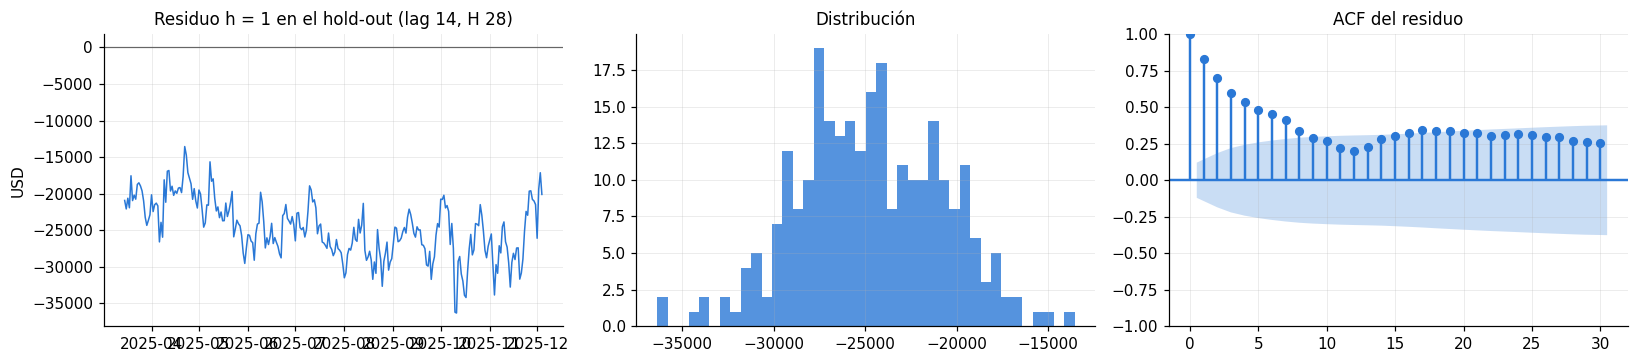

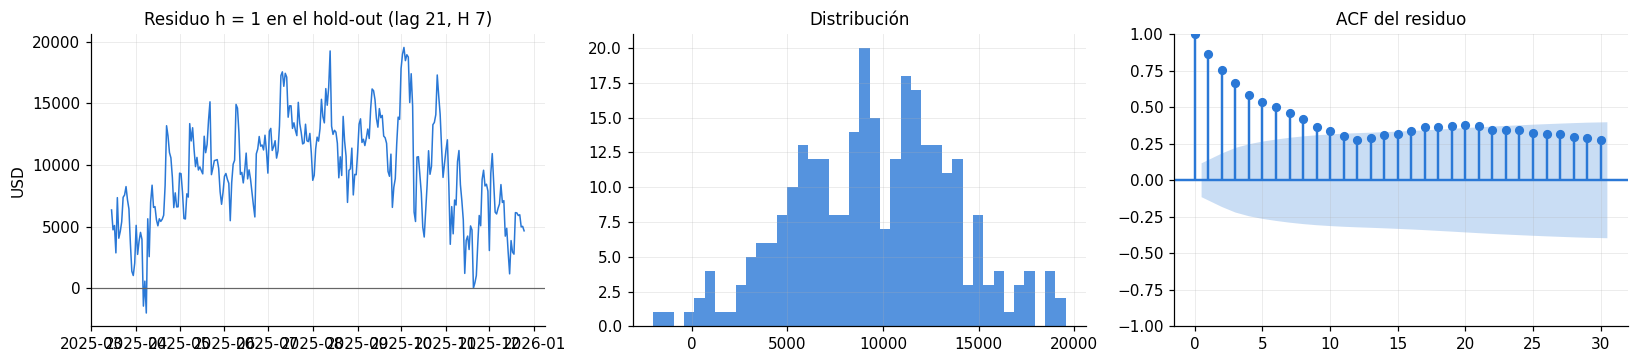

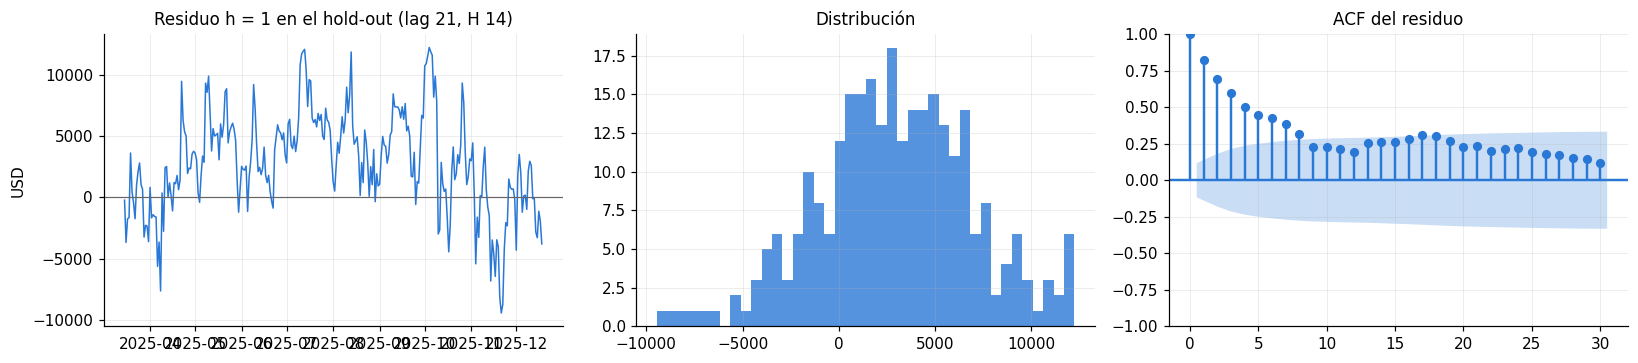

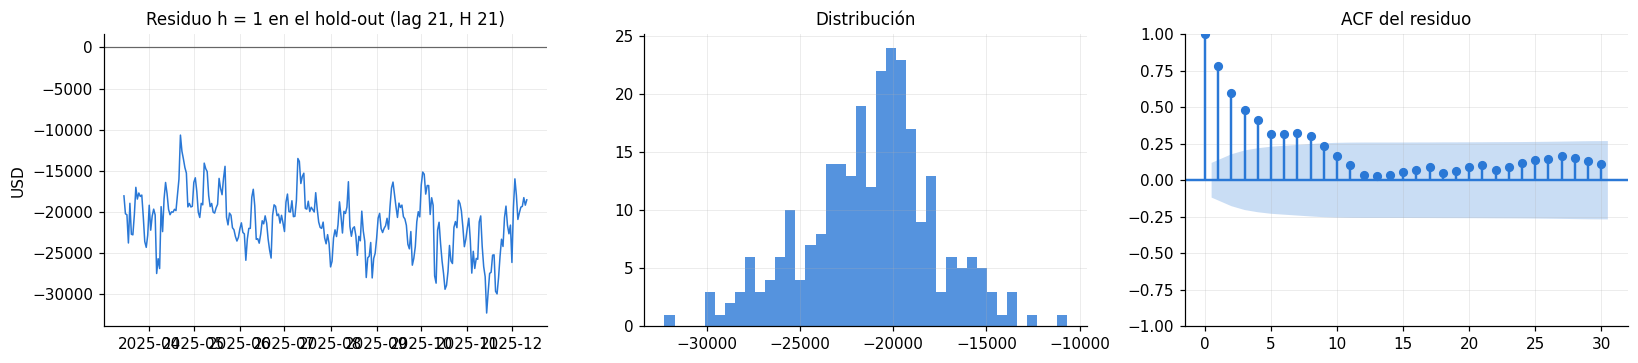

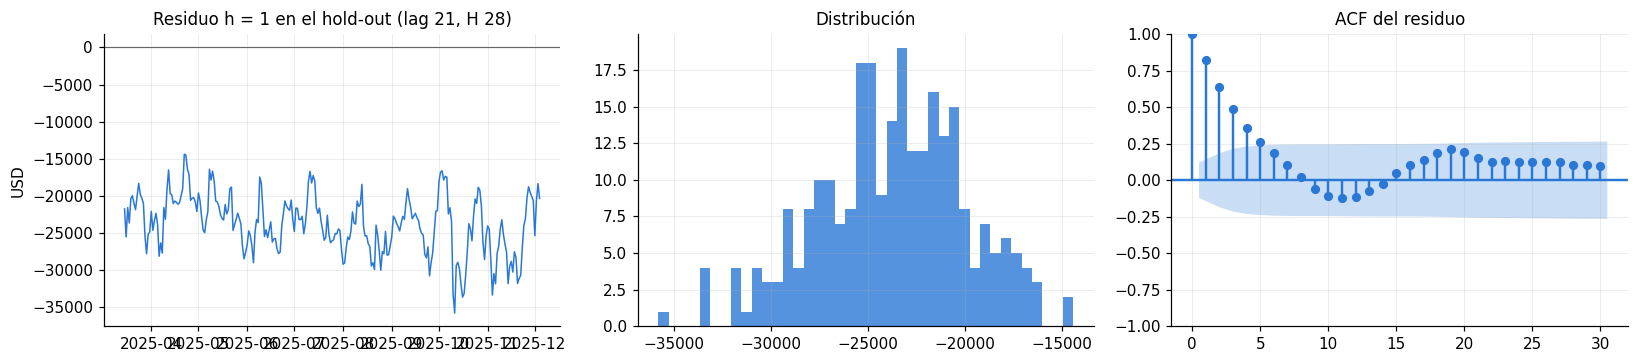

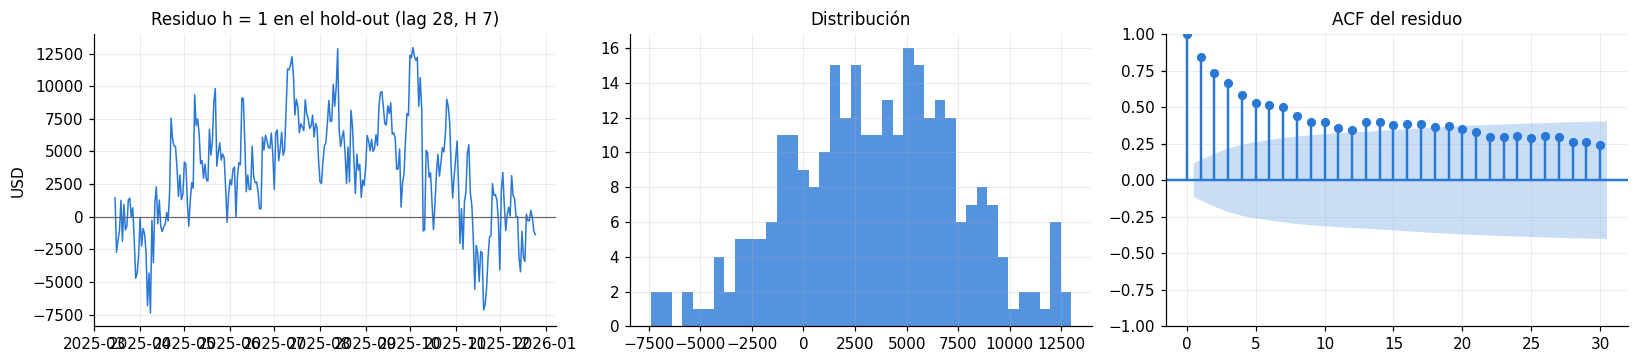

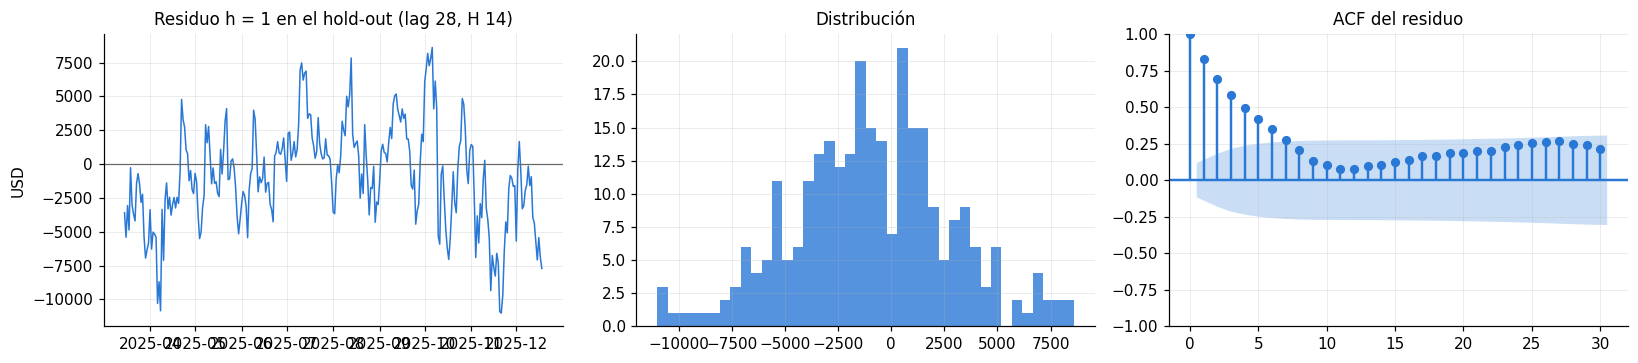

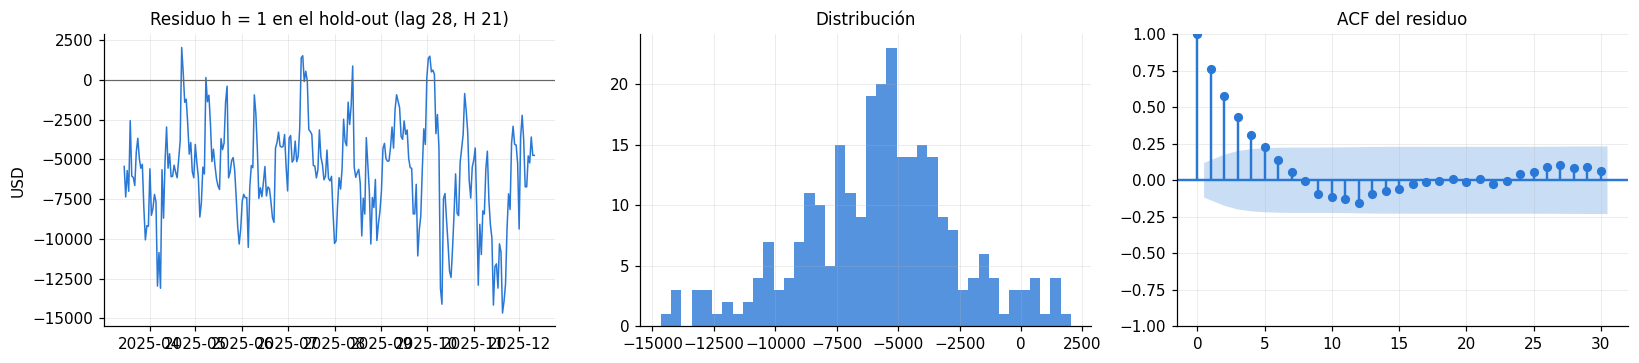

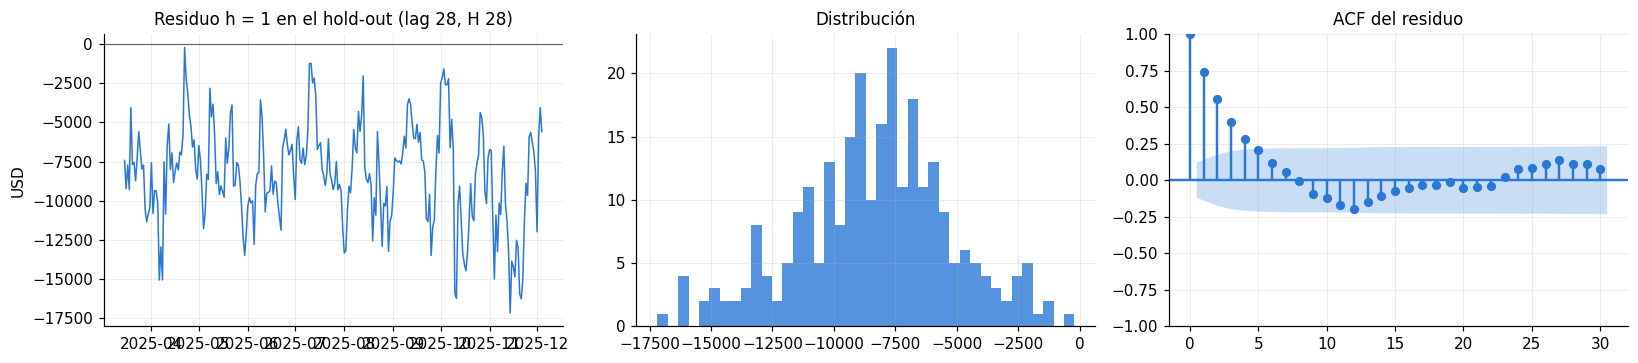

In [6]:
for (L, H) in sorted(RESID):
    if (L, H) != (14, 14):
        figura_residuos(L, H)

Las demás configuraciones repiten el diagnóstico con las cifras de la sección 4.2: Ljung-Box rechaza en todas y la media del residuo es distinta de cero en todas. En lag 28 con H 28, por ejemplo, el residuo queda por debajo de cero durante todo el hold-out (entre unos −17 500 y 0 USD), es decir, el modelo sobreestima el precio todos los días, y la ACF es 0.74 en el rezago 1 (lectura de la figura). En las cinco configuraciones con sesgo superior a 19 000 USD en valor absoluto (lag 7 con H 28, lag 14 con H 21 y H 28, lag 21 con H 21 y H 28) el desplazamiento domina por completo el error.

## 4.4 Síntesis

- En validación con Group K-Fold el promedio de p-valores BDS supera 0.05 en 12 de 16 configuraciones, pero la discontinuidad de los bloques de validación hace que esta prueba sea poco exigente.
- En el hold-out, BDS y Ljung-Box rechazan la independencia en las 16 configuraciones. La causa principal es un sesgo sistemático del modelo final, que supera los 19 000 USD en valor absoluto en cinco configuraciones, y la fuerte autocorrelación del residuo.
- La implicación para el modelado es concreta: el modelo debería predecir el cambio respecto al último precio (retornos) en vez del nivel, o incorporar una conexión directa con el último valor observado, de modo que la persistencia sea el punto de partida y la red solo aprenda la corrección.